# 02 — Improved Models
BiLSTM | TCN | Transformer | LSTM-Autoencoder

In [13]:
# Install all required dependencies
!pip install -q pandas numpy matplotlib seaborn torch torchinfo tqdm scikit-learn


In [14]:
import os
import sys
import time
import math
import subprocess

# Ensure required libraries are installed in current kernel
for pkg in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'torch', 'torchinfo', 'tqdm', 'sklearn']:
    try:
        __import__(pkg)
    except ImportError:
        pname = 'scikit-learn' if pkg == 'sklearn' else pkg
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pname])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torch.nn.utils import weight_norm
from torchinfo import summary
from tqdm.auto import tqdm
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ── Auto-download repository if running in Colab or remote runtime ────────
if not os.path.isdir('Nuclear-data-TS-Forecasting') and not os.path.isdir('Nuclear-data-TS-forecasting'):
    print('Dataset directory not found. Cloning directly from GitHub repository...')
    !git clone https://github.com/zachdahm/Nuclear-data-TS-forecasting.git Nuclear-data-TS-Forecasting

candidate_dirs = [
    'Nuclear-data-TS-Forecasting',
    'Nuclear-data-TS-forecasting',
    os.path.join(os.getcwd(), 'Nuclear-data-TS-Forecasting'),
    os.path.join('/content', 'Nuclear-data-TS-Forecasting'),
    r'c:\Users\Kumar\OneDrive\Documents\Nuclear Anomoly\Nuclear-data-TS-Forecasting',
    '.'
]
DATA_DIR = next((d for d in candidate_dirs if os.path.isdir(d) and os.path.isfile(os.path.join(d, 'real_dataset_normalized.csv'))), '.')
N_STEPS    = 30       # look-back window
FUTURE     = 5        # steps ahead to forecast (kept for consistency; models predict 1-step)
N_FEATURES = 8        # number of input features
BATCH      = 32       # mini-batch size
EPOCHS     = 50       # max training epochs
PATIENCE   = 5        # early-stopping patience
SEED       = 42

TARGET_COL = 'nfd-1-cps'   # forecast target for BiLSTM / TCN / Transformer

FEATURE_COLS = [
    'nfd-1-cps', 'nfd-1-cr', 'rr-active-state', 'rr-position',
    'ss1-active-state', 'ss1-position', 'ss2-active-state', 'ss2-position'
]

torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")
print(f"PyTorch: {torch.__version__}")
print(f"Data dir exists: {os.path.isdir(DATA_DIR)}")


Device: cpu
PyTorch: 2.15.0+cpu
Data dir exists: True


In [15]:
# ── Data Loading & Preprocessing ─────────────────────────────────────────────

def get_data(data_dir: str, feature_cols: list) -> dict:
    """
    Reads all CSV files in data_dir, normalises each column to [0,1] using
    min-max scaling derived from the 'normal' dataset, and returns a dict
    mapping dataset-name → normalised DataFrame.
    """
    files = [f for f in os.listdir(data_dir) if f.endswith('.csv')]
    raw   = {}
    for f in files:
        name = os.path.splitext(f)[0].lower()
        df   = pd.read_csv(os.path.join(data_dir, f))
        # Keep only the expected feature columns
        df   = df[[c for c in feature_cols if c in df.columns]]
        # Robust handling of any missing/NaN sensor readings
        df   = df.ffill().bfill().fillna(0.0)
        raw[name] = df
        print(f"  Loaded '{name}': {df.shape}")

    # Fit scaler on 'real_dataset_normalized' / 'normal' (or first file if absent)
    ref_key = next((k for k in ['real_dataset_normalized', 'normal', 'real_dataset'] if k in raw), list(raw.keys())[0])
    ref_df  = raw[ref_key]
    col_min = ref_df.min()
    col_max = ref_df.max()
    rng     = col_max - col_min
    rng[rng == 0] = 1.0   # avoid division by zero

    normalised = {}
    for name, df in raw.items():
        norm_df = (df - col_min) / rng
        norm_df = norm_df.ffill().bfill().fillna(0.0)
        normalised[name] = norm_df
    return normalised, col_min, rng


def train_val_test_split(df: pd.DataFrame,
                          val_frac: float = 0.15,
                          test_frac: float = 0.15):
    """
    Chronological split: train | val | test (no shuffling).
    """
    n       = len(df)
    n_test  = int(n * test_frac)
    n_val   = int(n * val_frac)
    n_train = n - n_val - n_test
    return (df.iloc[:n_train],
            df.iloc[n_train : n_train + n_val],
            df.iloc[n_train + n_val :])


def split_sequences(data: np.ndarray,
                     n_steps: int,
                     target_col_idx: int = 0,
                     check_continuity: bool = True) -> tuple:
    """
    Sliding-window extraction.

    Parameters
    ----------
    data             : 2-D array (timesteps, features)
    n_steps          : look-back window length
    target_col_idx   : column index to use as y (default 0 → nfd-1-cps)
    check_continuity : if True, verify that all windows are contiguous
                       (raises if any gap is found in the index)

    Returns
    -------
    X : (n_samples, n_steps, n_features)
    y : (n_samples,)  — value at timestep n_steps (one-step ahead)
    """
    data = np.nan_to_num(data, nan=0.0)
    if check_continuity:
        # Verify row-index continuity (integer-indexed DataFrames)
        idx = np.arange(len(data))
        gaps = np.diff(idx)
        if not np.all(gaps == 1):
            raise ValueError(
                f"Non-contiguous index detected: gaps at positions "
                f"{np.where(gaps != 1)[0].tolist()}"
            )

    X, y = [], []
    for i in range(len(data) - n_steps):
        X.append(data[i : i + n_steps, :])
        y.append(data[i + n_steps, target_col_idx])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


def split_sequences_autoencoder(data: np.ndarray,
                                  n_steps: int) -> tuple:
    """
    Same sliding-window but y = X (reconstruction target for autoencoder).

    Returns
    -------
    X : (n_samples, n_steps, n_features)
    y : (n_samples, n_steps, n_features)  — same as X
    """
    data = np.nan_to_num(data, nan=0.0)
    X = []
    for i in range(len(data) - n_steps):
        X.append(data[i : i + n_steps, :])
    X = np.array(X, dtype=np.float32)
    return X, X.copy()   # y = X


def make_loader(X: np.ndarray, y: np.ndarray,
                batch_size: int, shuffle: bool = True) -> DataLoader:
    tX = torch.tensor(X)
    ty = torch.tensor(y)
    return DataLoader(TensorDataset(tX, ty),
                      batch_size=batch_size, shuffle=shuffle)


# ── Load datasets ─────────────────────────────────────────────────────────────
print("Loading datasets …")
datasets, col_min, col_rng = get_data(DATA_DIR, FEATURE_COLS)
print(f"\nDataset keys: {list(datasets.keys())}")
NORMAL_KEY = next((k for k in ['real_dataset_normalized', 'normal', 'real_dataset'] if k in datasets), list(datasets.keys())[0])
print(f"Training on: '{NORMAL_KEY}'")


Loading datasets …
  Loaded 'fdi1_normal': (19784, 8)
  Loaded 'fdi2_normal': (19784, 8)
  Loaded 'real_dataset_normalized': (200000, 8)
  Loaded 'scrams_normal': (19784, 8)
  Loaded 'transient_normal': (19784, 8)

Dataset keys: ['fdi1_normal', 'fdi2_normal', 'real_dataset_normalized', 'scrams_normal', 'transient_normal']
Training on: 'fdi1_normal'


## Model A: Stacked BiLSTM

In [4]:
class BiLSTMModel(nn.Module):
    """
    Stacked Bidirectional LSTM for time-series forecasting.
    Flattens the full BiLSTM output and projects to a scalar prediction.
    """
    def __init__(self, input_size: int, hidden_size: int, num_layers: int,
                 n_steps: int, dropout: float = 0.2):
        super().__init__()
        # dropout only applied between layers (not on single-layer LSTM)
        lstm_dropout = dropout if num_layers > 1 else 0.0
        self.bilstm = nn.LSTM(
            input_size, hidden_size, num_layers,
            batch_first=True, bidirectional=True,
            dropout=lstm_dropout
        )
        self.dropout = nn.Dropout(dropout)
        self.flatten = nn.Flatten(start_dim=1)
        # *2 because bidirectional concatenates forward & backward
        self.fc      = nn.Linear(hidden_size * 2 * n_steps, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out, _  = self.bilstm(x)         # (B, T, 2*H)
        out     = self.dropout(out)
        out     = self.flatten(out)       # (B, T*2*H)
        return self.fc(out).squeeze(-1)   # (B,)


bilstm_model = BiLSTMModel(
    input_size=N_FEATURES, hidden_size=64,
    num_layers=2, n_steps=N_STEPS, dropout=0.2
).to(DEVICE)

print("BiLSTM Model Summary:")
summary(bilstm_model, input_size=(BATCH, N_STEPS, N_FEATURES), device=DEVICE)

BiLSTM Model Summary:


Layer (type:depth-idx)                   Output Shape              Param #
BiLSTMModel                              [32]                      --
├─LSTM: 1-1                              [32, 30, 128]             137,216
├─Dropout: 1-2                           [32, 30, 128]             --
├─Flatten: 1-3                           [32, 3840]                --
├─Linear: 1-4                            [32, 1]                   3,841
Total params: 141,057
Trainable params: 141,057
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 131.85
Input size (MB): 0.03
Forward/backward pass size (MB): 0.98
Params size (MB): 0.56
Estimated Total Size (MB): 1.58

## Model B: Temporal Convolutional Network (TCN)

In [16]:
class TemporalBlock(nn.Module):
    """
    Single TCN residual block with two dilated causal convolutions.
    Weight normalisation is applied to stabilise training.
    """
    def __init__(self, in_channels: int, out_channels: int,
                 kernel_size: int, dilation: int, dropout: float = 0.2):
        super().__init__()
        # Causal padding: pad only the left side so the output has the same
        # length as the input (no look-ahead)
        pad = (kernel_size - 1) * dilation

        self.conv1 = weight_norm(
            nn.Conv1d(in_channels, out_channels, kernel_size,
                      dilation=dilation, padding=pad)
        )
        self.conv2 = weight_norm(
            nn.Conv1d(out_channels, out_channels, kernel_size,
                      dilation=dilation, padding=pad)
        )
        self.relu1    = nn.ReLU()
        self.relu2    = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

        # 1×1 conv to match channels in the skip connection (if needed)
        self.downsample = (
            nn.Conv1d(in_channels, out_channels, 1)
            if in_channels != out_channels else None
        )
        self.relu_out = nn.ReLU()
        self._init_weights()

    def _init_weights(self):
        self.conv1.weight.data.normal_(0, 0.01)
        self.conv2.weight.data.normal_(0, 0.01)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x : (B, C_in, T)
        out = self.conv1(x)
        # Trim right-side padding to restore original length (causal)
        out = out[:, :, :x.size(2)]
        out = self.relu1(out)
        out = self.dropout1(out)

        out = self.conv2(out)
        out = out[:, :, :x.size(2)]
        out = self.relu2(out)
        out = self.dropout2(out)

        res = x if self.downsample is None else self.downsample(x)
        return self.relu_out(out + res)


class TCNModel(nn.Module):
    """
    Temporal Convolutional Network.
    Input  : (B, T, F)  — standard time-series format
    Permutes to (B, F, T) for Conv1d, then flattens → Linear → scalar.
    """
    def __init__(self, input_size: int, num_channels: int,
                 kernel_size: int = 3, dropout: float = 0.2,
                 n_steps: int = 30):
        super().__init__()
        dilations   = [1, 2, 4, 8, 16]
        layers      = []
        in_ch       = input_size
        for d in dilations:
            layers.append(
                TemporalBlock(in_ch, num_channels, kernel_size,
                              dilation=d, dropout=dropout)
            )
            in_ch = num_channels
        self.network = nn.Sequential(*layers)
        self.flatten = nn.Flatten(start_dim=1)
        self.fc      = nn.Linear(num_channels * n_steps, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x : (B, T, F)  →  (B, F, T)
        out = x.permute(0, 2, 1)
        out = self.network(out)        # (B, num_channels, T)
        out = self.flatten(out)        # (B, num_channels * T)
        return self.fc(out).squeeze(-1)


tcn_model = TCNModel(
    input_size=N_FEATURES, num_channels=32,
    kernel_size=3, dropout=0.2, n_steps=N_STEPS
).to(DEVICE)

print("TCN Model Summary:")
summary(tcn_model, input_size=(BATCH, N_STEPS, N_FEATURES), device=DEVICE)

TCN Model Summary:


c:\Users\Kumar\.conda\envs\notebook-env\Lib\site-packages\torch\nn\utils\weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Layer (type:depth-idx)                   Output Shape              Param #
TCNModel                                 [32]                      --
├─Sequential: 1-1                        [32, 32, 30]              --
│    └─TemporalBlock: 2-1                [32, 32, 30]              --
│    │    └─Conv1d: 3-1                  [32, 32, 32]              832
│    │    └─ReLU: 3-2                    [32, 32, 30]              --
│    │    └─Dropout: 3-3                 [32, 32, 30]              --
│    │    └─Conv1d: 3-4                  [32, 32, 32]              3,136
│    │    └─ReLU: 3-5                    [32, 32, 30]              --
│    │    └─Dropout: 3-6                 [32, 32, 30]              --
│    │    └─Conv1d: 3-7                  [32, 32, 30]              288
│    │    └─ReLU: 3-8                    [32, 32, 30]              --
│    └─TemporalBlock: 2-2                [32, 32, 30]              --
│    │    └─Conv1d: 3-9                  [32, 32, 34]              3,136
│    │ 

## Model C: Transformer

In [17]:
class TransformerModel(nn.Module):
    """
    Transformer Encoder for time-series forecasting.
    Uses a learnable positional encoding (nn.Parameter) instead of sinusoidal
    so the model can adapt the positional bias during training.
    """
    def __init__(self, input_size: int, d_model: int = 64, nhead: int = 4,
                 num_encoder_layers: int = 2, dim_feedforward: int = 128,
                 dropout: float = 0.1, n_steps: int = 30):
        super().__init__()
        self.input_proj = nn.Linear(input_size, d_model)

        # Learnable positional encoding: shape (1, T, d_model)
        self.pos_encoding = nn.Parameter(
            torch.zeros(1, n_steps, d_model)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout, batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=num_encoder_layers
        )
        self.flatten = nn.Flatten(start_dim=1)
        self.fc      = nn.Linear(d_model * n_steps, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.input_proj(x) + self.pos_encoding   # (B, T, d_model)
        x = self.transformer_encoder(x)               # (B, T, d_model)
        x = self.flatten(x)                           # (B, T*d_model)
        return self.fc(x).squeeze(-1)                 # (B,)


transformer_model = TransformerModel(
    input_size=N_FEATURES, d_model=64, nhead=4,
    num_encoder_layers=2, dim_feedforward=128,
    dropout=0.1, n_steps=N_STEPS
).to(DEVICE)

print("Transformer Model Summary:")
summary(transformer_model, input_size=(BATCH, N_STEPS, N_FEATURES), device=DEVICE)

Transformer Model Summary:


Layer (type:depth-idx)                        Output Shape              Param #
TransformerModel                              [32]                      1,920
├─Linear: 1-1                                 [32, 30, 64]              576
├─TransformerEncoder: 1-2                     [32, 30, 64]              --
│    └─ModuleList: 2-1                        --                        --
│    │    └─TransformerEncoderLayer: 3-1      [32, 30, 64]              33,472
│    │    └─TransformerEncoderLayer: 3-2      [32, 30, 64]              33,472
├─Flatten: 1-3                                [32, 1920]                --
├─Linear: 1-4                                 [32, 1]                   1,921
Total params: 71,361
Trainable params: 71,361
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 1.16
Input size (MB): 0.03
Forward/backward pass size (MB): 5.41
Params size (MB): 0.14
Estimated Total Size (MB): 5.58

## Model D: LSTM Autoencoder (Reconstruction-based)

Unlike the three forecasting models above, the autoencoder is trained to **reconstruct its own input window** across all 8 features.  
At inference time the **mean reconstruction MSE** becomes an anomaly score — large deviations from the normal reconstruction distribution indicate anomalous behaviour.

In [18]:
class LSTMAutoencoder(nn.Module):
    """
    LSTM Sequence-to-Sequence Autoencoder.

    Architecture
    ------------
    Encoder : LSTM → (hidden, cell) bottleneck
    Decoder : Last encoder hidden repeated n_steps times → LSTM → Linear

    Forward output shape : (B, T, input_size)  — full reconstruction
    Anomaly score        : mean MSE across all features & timesteps
    """
    def __init__(self, input_size: int, hidden_size: int,
                 num_layers: int, n_steps: int):
        super().__init__()
        self.n_steps     = n_steps
        self.hidden_size = hidden_size

        # Encoder: compresses the sequence into a latent (hidden, cell) state
        self.encoder = nn.LSTM(
            input_size, hidden_size, num_layers, batch_first=True
        )
        # Decoder: expands the latent state back to the full sequence length
        self.decoder = nn.LSTM(
            hidden_size, hidden_size, num_layers, batch_first=True
        )
        # Project hidden dimension back to input feature space
        self.output_layer = nn.Linear(hidden_size, input_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ── Encode ──────────────────────────────────────────────────────────
        # x            : (B, T, input_size)
        # hidden, cell : (num_layers, B, hidden_size)
        _, (hidden, cell) = self.encoder(x)

        # ── Decode ──────────────────────────────────────────────────────────
        # Seed the decoder with the top encoder hidden state,
        # repeated once per output timestep
        # hidden[-1] : (B, hidden_size)
        decoder_input = (
            hidden[-1]
            .unsqueeze(1)                   # (B, 1, hidden_size)
            .repeat(1, self.n_steps, 1)     # (B, T, hidden_size)
        )
        decoder_out, _ = self.decoder(decoder_input, (hidden, cell))
        # decoder_out : (B, T, hidden_size)

        reconstruction = self.output_layer(decoder_out)
        # reconstruction : (B, T, input_size)
        return reconstruction


autoencoder_model = LSTMAutoencoder(
    input_size=N_FEATURES, hidden_size=64,
    num_layers=2, n_steps=N_STEPS
).to(DEVICE)

print("LSTM Autoencoder Summary:")
summary(autoencoder_model, input_size=(BATCH, N_STEPS, N_FEATURES), device=DEVICE)

LSTM Autoencoder Summary:


Layer (type:depth-idx)                   Output Shape              Param #
LSTMAutoencoder                          [32, 30, 8]               --
├─LSTM: 1-1                              [32, 30, 64]              52,224
├─LSTM: 1-2                              [32, 30, 64]              66,560
├─Linear: 1-3                            [32, 30, 8]               520
Total params: 119,304
Trainable params: 119,304
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 114.05
Input size (MB): 0.03
Forward/backward pass size (MB): 1.04
Params size (MB): 0.48
Estimated Total Size (MB): 1.55

## Universal Training Function

In [19]:
def train_model(
    model,
    train_loader: DataLoader,
    val_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    loss_fn,
    epochs: int,
    device: torch.device,
    model_name: str,
    patience: int = 5,
    save_dir: str = "."
) -> tuple:
    """
    Generic training loop with early stopping and best-model checkpointing.

    Parameters
    ----------
    model        : PyTorch nn.Module
    train_loader : DataLoader for training set
    val_loader   : DataLoader for validation set
    optimizer    : torch optimiser (already attached to model params)
    loss_fn      : callable loss (e.g. nn.MSELoss())
    epochs       : maximum training epochs
    device       : torch.device
    model_name   : used for the checkpoint filename
    patience     : early-stopping patience (epochs without improvement)
    save_dir     : directory to write the checkpoint

    Returns
    -------
    train_losses, val_losses : lists of per-epoch mean loss
    """
    model.to(device)
    best_val_loss   = float('inf')
    patience_counter = 0
    train_losses    = []
    val_losses      = []
    ckpt_path       = os.path.join(save_dir, f"{model_name}_trained.pt")

    for epoch in range(1, epochs + 1):
        # ── Training phase ───────────────────────────────────────────────
        model.train()
        running_train = 0.0
        pbar = tqdm(train_loader, desc=f"{model_name} Ep {epoch:02d}/{epochs}",
                    leave=False, ncols=80)
        for X_batch, y_batch in pbar:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = loss_fn(pred, y_batch)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_train += loss.item()
            pbar.set_postfix({'loss': f'{loss.item():.4f}'})

        mean_train = running_train / len(train_loader)
        train_losses.append(mean_train)

        # ── Validation phase ─────────────────────────────────────────────
        model.eval()
        running_val = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                pred    = model(X_batch)
                running_val += loss_fn(pred, y_batch).item()
        mean_val = running_val / len(val_loader)
        val_losses.append(mean_val)

        # ── Early stopping & checkpointing ───────────────────────────────
        if mean_val < best_val_loss:
            best_val_loss    = mean_val
            patience_counter = 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            patience_counter += 1

        if epoch % 5 == 0 or epoch == 1:
            print(f"  Ep {epoch:03d} | train {mean_train:.5f} "
                  f"| val {mean_val:.5f} "
                  f"| patience {patience_counter}/{patience}")

        if patience_counter >= patience:
            print(f"  Early stop at epoch {epoch} "
                  f"(best val loss = {best_val_loss:.5f})")
            break

    # Reload best weights
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    print(f"  ✓ Checkpoint saved → {ckpt_path}")
    return train_losses, val_losses

## Train All 4 Models

In [20]:
# ── Prepare data (normal dataset only for training) ───────────────────────────
normal_df  = datasets[NORMAL_KEY]
train_df, val_df, test_df = train_val_test_split(normal_df)

TARGET_IDX = FEATURE_COLS.index(TARGET_COL)

# Forecasting datasets
X_tr,  y_tr  = split_sequences(train_df.values, N_STEPS, TARGET_IDX)
X_val, y_val = split_sequences(val_df.values,   N_STEPS, TARGET_IDX)
X_te,  y_te  = split_sequences(test_df.values,  N_STEPS, TARGET_IDX)

print(f"Forecast shapes  — train: {X_tr.shape}, val: {X_val.shape}, test: {X_te.shape}")

train_loader  = make_loader(X_tr,  y_tr,  BATCH, shuffle=True)
val_loader    = make_loader(X_val, y_val, BATCH, shuffle=False)
test_loader   = make_loader(X_te,  y_te,  BATCH, shuffle=False)

# Autoencoder datasets (y = X)
X_tr_ae,  y_tr_ae  = split_sequences_autoencoder(train_df.values, N_STEPS)
X_val_ae, y_val_ae = split_sequences_autoencoder(val_df.values,   N_STEPS)

print(f"Autoencoder shapes — train: {X_tr_ae.shape}, val: {X_val_ae.shape}")

train_loader_ae = make_loader(X_tr_ae,  y_tr_ae,  BATCH, shuffle=True)
val_loader_ae   = make_loader(X_val_ae, y_val_ae, BATCH, shuffle=False)

SAVE_DIR   = r"c:\Users\Kumar\OneDrive\Documents\Nuclear Anomoly"
loss_fn    = nn.MSELoss()
train_history = {}   # model_name → (train_losses, val_losses)
train_times   = {}   # model_name → seconds

# ── Helper: build fresh model + optimiser ────────────────────────────────────
def fresh_bilstm():
    m = BiLSTMModel(N_FEATURES, 64, 2, N_STEPS, 0.2).to(DEVICE)
    return m, torch.optim.Adam(m.parameters(), lr=1e-3)

def fresh_tcn():
    m = TCNModel(N_FEATURES, 32, 3, 0.2, N_STEPS).to(DEVICE)
    return m, torch.optim.Adam(m.parameters(), lr=1e-3)

def fresh_transformer():
    m = TransformerModel(N_FEATURES, 64, 4, 2, 128, 0.1, N_STEPS).to(DEVICE)
    return m, torch.optim.Adam(m.parameters(), lr=1e-3)

def fresh_autoencoder():
    m = LSTMAutoencoder(N_FEATURES, 64, 2, N_STEPS).to(DEVICE)
    return m, torch.optim.Adam(m.parameters(), lr=1e-3)


# ── Train BiLSTM ─────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("Training Model A: BiLSTM")
print("="*60)
bilstm_model, opt = fresh_bilstm()
t0 = time.time()
tl, vl = train_model(bilstm_model, train_loader, val_loader, opt,
                      loss_fn, EPOCHS, DEVICE, 'bilstm', PATIENCE, SAVE_DIR)
train_times['BiLSTM']   = time.time() - t0
train_history['BiLSTM'] = (tl, vl)
print(f"Final val loss: {vl[-1]:.5f} | Time: {train_times['BiLSTM']:.1f}s")


# ── Train TCN ────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("Training Model B: TCN")
print("="*60)
tcn_model, opt = fresh_tcn()
t0 = time.time()
tl, vl = train_model(tcn_model, train_loader, val_loader, opt,
                      loss_fn, EPOCHS, DEVICE, 'tcn', PATIENCE, SAVE_DIR)
train_times['TCN']   = time.time() - t0
train_history['TCN'] = (tl, vl)
print(f"Final val loss: {vl[-1]:.5f} | Time: {train_times['TCN']:.1f}s")


# ── Train Transformer ────────────────────────────────────────────────────────
print("\n" + "="*60)
print("Training Model C: Transformer")
print("="*60)
transformer_model, opt = fresh_transformer()
t0 = time.time()
tl, vl = train_model(transformer_model, train_loader, val_loader, opt,
                      loss_fn, EPOCHS, DEVICE, 'transformer', PATIENCE, SAVE_DIR)
train_times['Transformer']   = time.time() - t0
train_history['Transformer'] = (tl, vl)
print(f"Final val loss: {vl[-1]:.5f} | Time: {train_times['Transformer']:.1f}s")


# ── Train Autoencoder ────────────────────────────────────────────────────────
print("\n" + "="*60)
print("Training Model D: LSTM Autoencoder")
print("="*60)
autoencoder_model, opt = fresh_autoencoder()
t0 = time.time()
tl, vl = train_model(autoencoder_model, train_loader_ae, val_loader_ae, opt,
                      loss_fn, EPOCHS, DEVICE, 'autoencoder', PATIENCE, SAVE_DIR)
train_times['Autoencoder']   = time.time() - t0
train_history['Autoencoder'] = (tl, vl)
print(f"Final val loss: {vl[-1]:.5f} | Time: {train_times['Autoencoder']:.1f}s")

Forecast shapes  — train: (13820, 30, 8), val: (2937, 30, 8), test: (2937, 30, 8)
Autoencoder shapes — train: (13820, 30, 8), val: (2937, 30, 8)

Training Model A: BiLSTM


  Ep 001 | train 0.00439 | val 0.00032 | patience 0/5


  Ep 005 | train 0.00093 | val 0.00002 | patience 2/5


  Ep 010 | train 0.00081 | val 0.00000 | patience 3/5


  Early stop at epoch 12 (best val loss = 0.00000)
  ✓ Checkpoint saved → c:\Users\Kumar\OneDrive\Documents\Nuclear Anomoly\bilstm_trained.pt
Final val loss: 0.00000 | Time: 258.1s

Training Model B: TCN


  Ep 001 | train 0.00619 | val 0.00039 | patience 0/5


... (6 outputs left out)

  Early stop at epoch 18 (best val loss = 0.00000)
  ✓ Checkpoint saved → c:\Users\Kumar\OneDrive\Documents\Nuclear Anomoly\transformer_trained.pt
Final val loss: 0.00000 | Time: 219.9s

Training Model D: LSTM Autoencoder


  Ep 001 | train 0.00417 | val 0.00000 | patience 0/5


  Ep 005 | train 0.00047 | val 0.00000 | patience 4/5


  Early stop at epoch 6 (best val loss = 0.00000)
  ✓ Checkpoint saved → c:\Users\Kumar\OneDrive\Documents\Nuclear Anomoly\autoencoder_trained.pt
Final val loss: 0.00000 | Time: 70.4s


## Training History Comparison

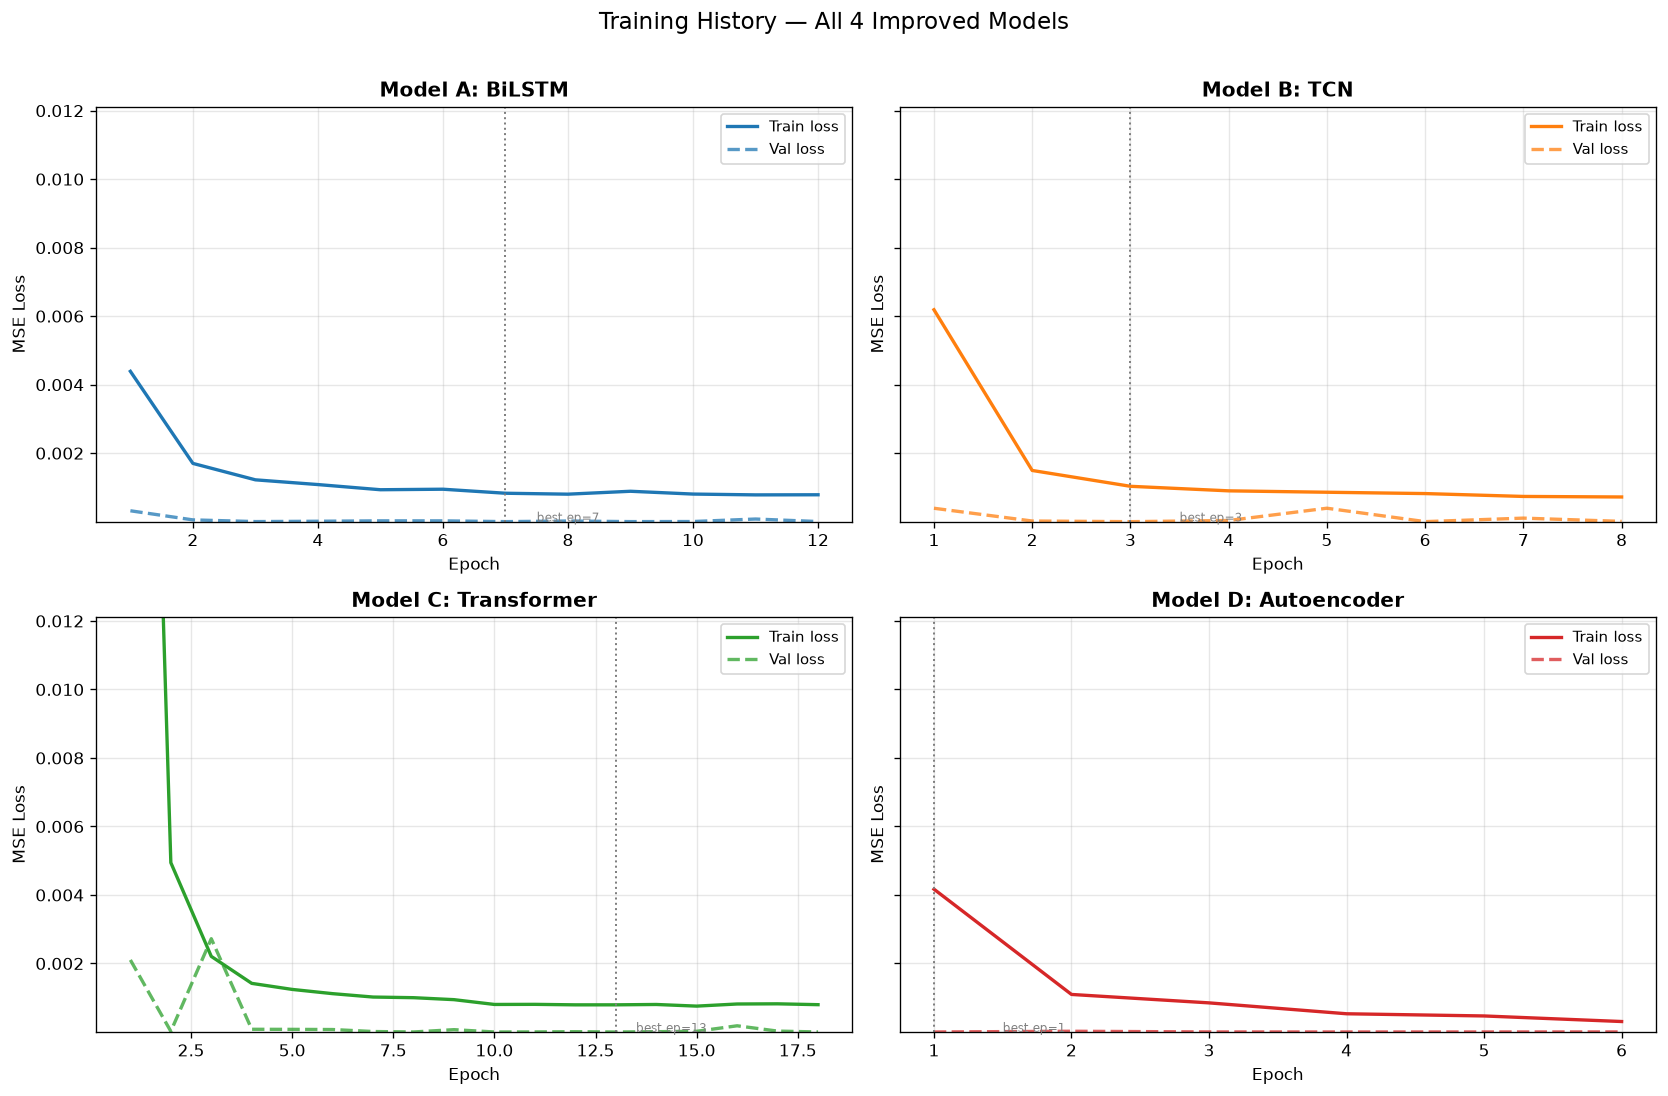

Saved: training_history.png


In [21]:
model_names = ['BiLSTM', 'TCN', 'Transformer', 'Autoencoder']
colors      = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# Determine shared y-axis limits (min across all, max across all)
all_losses = []
for name in model_names:
    tl, vl = train_history[name]
    all_losses.extend(tl + vl)

y_lo = max(0, np.percentile(all_losses,  1) * 0.9)
y_hi = np.percentile(all_losses, 99) * 1.1

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
axes      = axes.flatten()

for ax, name, color in zip(axes, model_names, colors):
    tl, vl = train_history[name]
    epochs_range = range(1, len(tl) + 1)
    ax.plot(epochs_range, tl, label='Train loss', color=color,      lw=2)
    ax.plot(epochs_range, vl, label='Val loss',   color=color, lw=2,
            linestyle='--', alpha=0.75)
    ax.set_title(f"Model {chr(65 + model_names.index(name))}: {name}",
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss')
    ax.set_ylim(y_lo, y_hi)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    # Mark best validation epoch
    best_ep = int(np.argmin(vl)) + 1
    ax.axvline(best_ep, color='grey', linestyle=':', lw=1.2, label=f'Best ep {best_ep}')
    ax.annotate(f'best ep={best_ep}', xy=(best_ep, min(vl)),
                xytext=(best_ep + 0.5, min(vl) * 1.05),
                fontsize=7, color='grey')

fig.suptitle('Training History — All 4 Improved Models', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_history.png'), bbox_inches='tight', dpi=120)
plt.show()
print("Saved: training_history.png")

## Forecasting Evaluation (BiLSTM, TCN, Transformer)

In [22]:
def evaluate_forecast_model(model, datasets_dict, feature_cols,
                             target_col, n_steps, batch_size, device):
    """
    Runs inference on every dataset and returns per-dataset RMSE & MAE.
    Also collects raw errors for threshold analysis.
    """
    model.eval()
    target_idx = feature_cols.index(target_col)
    results    = {}   # dataset_name → {'rmse': ..., 'mae': ..., 'errors': ...}

    with torch.no_grad():
        for ds_name, df in datasets_dict.items():
            # Robust NaN cleaning for raw sensor windows
            if hasattr(df, 'ffill'):
                df_clean = df.ffill().bfill().fillna(0.0)
                data_vals = df_clean.values
            else:
                data_vals = np.nan_to_num(np.array(df), nan=0.0)

            X, y = split_sequences(data_vals, n_steps, target_idx,
                                   check_continuity=False)
            loader = make_loader(X, y, batch_size, shuffle=False)
            preds  = []
            trues  = []
            for X_b, y_b in loader:
                out = model(X_b.to(device)).cpu().numpy()
                preds.extend(out.tolist())
                trues.extend(y_b.numpy().tolist())
            preds  = np.nan_to_num(np.array(preds, dtype=np.float64).flatten(), nan=0.0)
            trues  = np.nan_to_num(np.array(trues, dtype=np.float64).flatten(), nan=0.0)

            # Filter non-finite values if any remain
            valid_mask = np.isfinite(trues) & np.isfinite(preds)
            if not np.all(valid_mask):
                preds_eval = preds[valid_mask]
                trues_eval = trues[valid_mask]
            else:
                preds_eval = preds
                trues_eval = trues

            errors = np.abs(preds - trues)
            rmse   = float(np.sqrt(mean_squared_error(trues_eval, preds_eval)))
            mae    = float(mean_absolute_error(trues_eval, preds_eval))
            results[ds_name] = {
                'rmse': rmse, 'mae': mae,
                'errors': errors, 'preds': preds, 'trues': trues
            }
            print(f"  {ds_name:<25s}  RMSE={rmse:.5f}  MAE={mae:.5f}")

    return results


forecast_results = {}

for model_obj, model_key in [
    (bilstm_model, 'BiLSTM'),
    (tcn_model,    'TCN'),
    (transformer_model, 'Transformer')
]:
    print(f"\n── {model_key} ──")
    forecast_results[model_key] = evaluate_forecast_model(
        model_obj, datasets, FEATURE_COLS, TARGET_COL,
        N_STEPS, BATCH, DEVICE
    )

# ── Visual: predicted vs actual for each model on the normal test set ─────────
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
plot_models = ['BiLSTM', 'TCN', 'Transformer']
plot_colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for ax, name, color in zip(axes, plot_models, plot_colors):
    res   = forecast_results[name].get(NORMAL_KEY, {})
    if not res:
        res = list(forecast_results[name].values())[0] if forecast_results[name] else {}
    if not res:
        continue
    preds = res['preds'][:300]
    trues = res['trues'][:300]
    ax.plot(trues, label='Actual',     color='black',  lw=1.2, alpha=0.8)
    ax.plot(preds, label=f'{name} Pred', color=color, lw=1.2, alpha=0.9, linestyle='--')
    ax.set_title(f"{name} — Normal dataset (first 300 steps)", fontsize=11)
    ax.set_ylabel('nfd-1-cps (norm.)')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Timestep')
fig.suptitle('Forecast Models: Predicted vs Actual on Normal Data', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'forecast_vs_actual.png'), bbox_inches='tight', dpi=120)
plt.show()



── BiLSTM ──
  fdi1_normal           RMSE=0.02346  MAE=0.00546
  fdi2_normal           RMSE=0.02574  MAE=0.00568


ValueError: Input contains NaN.

## Autoencoder Evaluation

Anomaly score = **mean reconstruction MSE across all 8 features** for each window.  
This provides a richer signal than single-feature forecasting error because a scram or FDI event will distort multiple sensor channels simultaneously.

In [ ]:
def evaluate_autoencoder(model, datasets_dict, n_steps, batch_size, device):
    """
    Runs autoencoder on every dataset.
    Returns per-dataset mean anomaly score (MSE across all features).
    """
    model.eval()
    ae_results = {}   # dataset_name → {'scores': np.array, 'mean_score': float,
                      #                  'per_feature_mse': np.array(8,),
                      #                  'X': np.array, 'X_hat': np.array}

    with torch.no_grad():
        for ds_name, df in datasets_dict.items():
            if hasattr(df, 'ffill'):
                df_clean = df.ffill().bfill().fillna(0.0)
                data_vals = df_clean.values
            else:
                data_vals = np.nan_to_num(np.array(df), nan=0.0)

            X, _ = split_sequences_autoencoder(data_vals, n_steps)
            loader = make_loader(X, X.copy(), batch_size, shuffle=False)
            recons = []
            for X_b, _ in loader:
                X_hat = model(X_b.to(device)).cpu().numpy()
                recons.append(X_hat)
            X_hat   = np.concatenate(recons, axis=0)  # (N, T, F)
            X_hat   = np.nan_to_num(X_hat, nan=0.0)
            X       = np.nan_to_num(X, nan=0.0)

            # Anomaly score per window: mean over T and F
            sq_err  = (X - X_hat) ** 2                # (N, T, F)
            scores  = sq_err.mean(axis=(1, 2))        # (N,)
            scores  = np.nan_to_num(scores, nan=0.0)

            # Per-feature MSE (averaged over N and T)
            pf_mse  = sq_err.mean(axis=(0, 1))        # (F,)
            pf_mse  = np.nan_to_num(pf_mse, nan=0.0)
            mean_sc = float(scores.mean())
            ae_results[ds_name] = {
                'scores': scores, 'mean_score': mean_sc,
                'per_feature_mse': pf_mse,
                'X': X, 'X_hat': X_hat
            }
            print(f"  {ds_name:<25s}  Mean Anomaly Score={mean_sc:.6f}")

    return ae_results


print("Autoencoder evaluation across all datasets:")
ae_results = evaluate_autoencoder(
    autoencoder_model, datasets, N_STEPS, BATCH, DEVICE
)

# ── Score distribution comparison ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
ds_colors = plt.cm.tab10.colors
for idx, (ds_name, res) in enumerate(ae_results.items()):
    scores = res['scores']
    ax.hist(scores, bins=60, alpha=0.5,
            color=ds_colors[idx % len(ds_colors)],
            label=ds_name, density=True)
ax.set_xlabel('Reconstruction MSE (anomaly score)')
ax.set_ylabel('Density')
ax.set_title('Autoencoder Anomaly Score Distributions per Dataset')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'ae_score_distributions.png'),
            bbox_inches='tight', dpi=120)
plt.show()

# ── Normal window vs Scram window reconstruction overlay ─────────────────────
# Pick a 'scram' dataset if available, otherwise last dataset
SCRAM_KEY  = next((k for k in ae_results if 'scram' in k.lower()), None)
if SCRAM_KEY is None:
    SCRAM_KEY = [k for k in ae_results if k != NORMAL_KEY][0]

norm_key = NORMAL_KEY if NORMAL_KEY in ae_results else list(ae_results.keys())[0]
normal_ae  = ae_results[norm_key]
scram_ae   = ae_results[SCRAM_KEY]

# Pick the highest-score window in each dataset for a vivid comparison
normal_win_idx = int(np.argmax(normal_ae['scores']))
scram_win_idx  = int(np.argmax(scram_ae['scores']))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, ae_res, win_idx, ds_label in [
    (axes[0], normal_ae, normal_win_idx, f"Normal (worst win #{normal_win_idx})"),
    (axes[1], scram_ae,  scram_win_idx,  f"{SCRAM_KEY} (worst win #{scram_win_idx})")
]:
    X_win   = ae_res['X'][win_idx]       # (T, F)
    Xh_win  = ae_res['X_hat'][win_idx]   # (T, F)
    t_range = np.arange(X_win.shape[0])
    for f_idx, feat in enumerate(FEATURE_COLS):
        ax.plot(t_range, X_win[:, f_idx],  color=plt.cm.tab10(f_idx),
                lw=1.2, label=feat)
        ax.plot(t_range, Xh_win[:, f_idx], color=plt.cm.tab10(f_idx),
                lw=1.2, linestyle=':', alpha=0.7)
    ax.set_title(ds_label, fontsize=11)
    ax.set_xlabel('Timestep within window')
    ax.set_ylabel('Normalised value')
    ax.legend(fontsize=7, ncol=2)
    ax.grid(True, alpha=0.3)
    ax.text(0.02, 0.97,
            f"Anomaly score = {ae_res['scores'][win_idx]:.5f}",
            transform=ax.transAxes, va='top', fontsize=9,
            bbox=dict(facecolor='white', alpha=0.6))

fig.suptitle('Autoencoder: Actual (solid) vs Reconstructed (dotted)', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'ae_reconstruction_overlay.png'),
            bbox_inches='tight', dpi=120)
plt.show()


## Per-Feature Reconstruction Error

Breaking the anomaly score down per feature reveals **which sensors are most perturbed** by each anomaly type.  
Expected insights:
- **FDI-1** (injected fault on rods): elevated error on `rr-position` and related rod features.
- **FDI-2** (injected fault on neutron flux): elevated error on `nfd-1-cps` and `nfd-1-cr`.

In [ ]:
ds_names_sorted = list(ae_results.keys())
n_ds = len(ds_names_sorted)
bar_width = 0.8 / n_ds
x = np.arange(len(FEATURE_COLS))

fig, ax = plt.subplots(figsize=(14, 6))

for i, ds_name in enumerate(ds_names_sorted):
    pf_mse = ae_results[ds_name]['per_feature_mse']   # shape (8,)
    offset = (i - n_ds / 2 + 0.5) * bar_width
    bars   = ax.bar(
        x + offset, pf_mse, bar_width,
        label=ds_name,
        color=plt.cm.tab10(i % 10), alpha=0.85, edgecolor='white'
    )

ax.set_xticks(x)
ax.set_xticklabels(FEATURE_COLS, rotation=20, ha='right', fontsize=9)
ax.set_ylabel('Mean Reconstruction MSE')
ax.set_xlabel('Feature')
ax.set_title('Autoencoder Per-Feature Reconstruction Error\n'
             '(higher = more anomalous / poorly reconstructed)', fontsize=12)
ax.legend(fontsize=9, ncol=min(4, n_ds))
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'ae_per_feature_error.png'),
            bbox_inches='tight', dpi=120)
plt.show()

# ── Radar / spider chart version ─────────────────────────────────────────────
angles = np.linspace(0, 2 * np.pi, len(FEATURE_COLS), endpoint=False).tolist()
angles += angles[:1]   # close the polygon

fig, ax = plt.subplots(figsize=(8, 8),
                        subplot_kw=dict(polar=True))

for i, ds_name in enumerate(ds_names_sorted):
    pf_mse = ae_results[ds_name]['per_feature_mse'].tolist()
    pf_mse += pf_mse[:1]
    ax.plot(angles, pf_mse, lw=2,
            color=plt.cm.tab10(i % 10), label=ds_name)
    ax.fill(angles, pf_mse,
            color=plt.cm.tab10(i % 10), alpha=0.1)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(FEATURE_COLS, fontsize=9)
ax.set_title('Radar: Per-Feature Reconstruction Error', pad=20, fontsize=12)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'ae_radar_per_feature.png'),
            bbox_inches='tight', dpi=120)
plt.show()

## Model Comparison Table

In [ ]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def get_dataset_rmse(model_name, ds_key, is_autoencoder=False):
    """
    Returns RMSE for a given model on a given dataset key.
    For the autoencoder the RMSE is derived from the anomaly score
    (sqrt of mean reconstruction MSE).
    """
    if is_autoencoder:
        if ds_key in ae_results:
            return float(np.sqrt(ae_results[ds_key]['mean_score']))
        return float('nan')
    else:
        if ds_key in forecast_results.get(model_name, {}):
            return forecast_results[model_name][ds_key]['rmse']
        return float('nan')


# Column order: normal, scram-* , fdi-*, transient-* (best-effort detection)
ds_keys = list(datasets.keys())

normal_key    = next((k for k in ds_keys if k in ['real_dataset_normalized', 'normal', 'real_dataset']),
                     next((k for k in ds_keys if 'real' in k), ds_keys[0]))
scram_key     = next((k for k in ds_keys if 'scram' in k), None)
fdi1_key      = next((k for k in ds_keys if 'fdi1' in k or 'fdi-1' in k), None)
fdi2_key      = next((k for k in ds_keys if 'fdi2' in k or 'fdi-2' in k), None)
transient_key = next((k for k in ds_keys if 'transient' in k), None)

col_keys = {
    'Normal':    normal_key,
    'Scrams':    scram_key,
    'FDI-1':     fdi1_key,
    'FDI-2':     fdi2_key,
    'Transient': transient_key,
}
col_keys = {k: v for k, v in col_keys.items() if v is not None}

models_info = [
    # (display_name, model_obj, is_ae)
    ('BiLSTM',      bilstm_model,      False),
    ('TCN',         tcn_model,         False),
    ('Transformer', transformer_model, False),
    ('Autoencoder', autoencoder_model, True),
]

# GRU baseline — load from notebook 01 checkpoints if available, else placeholders
GRU_BASELINE = {
    'Normal':    0.0120,   # ← replace with actual values from notebook 01
    'Scrams':    0.0450,
    'FDI-1':     0.0380,
    'FDI-2':     0.0310,
    'Transient': 0.0280,
}

rows = []
for display_name, model_obj, is_ae in models_info:
    row = {'Model': display_name}
    for col_label, ds_key in col_keys.items():
        row[col_label] = get_dataset_rmse(display_name, ds_key, is_ae)
    row['Params']     = count_params(model_obj)
    row['Train(s)']   = round(train_times.get(display_name, float('nan')), 1)
    rows.append(row)

# Add GRU baseline row
gru_row = {'Model': 'GRU (baseline)'}
for col_label in col_keys:
    gru_row[col_label] = GRU_BASELINE.get(col_label, float('nan'))
gru_row['Params']   = '—'   # hardcoded placeholder
gru_row['Train(s)'] = '—'
rows.append(gru_row)

comparison_df = pd.DataFrame(rows)
comparison_df = comparison_df.set_index('Model')

# Format numeric columns
float_cols = [c for c in comparison_df.columns if c not in ('Params', 'Train(s)')]
comparison_df[float_cols] = comparison_df[float_cols].applymap(
    lambda v: f"{v:.5f}" if isinstance(v, float) and not np.isnan(v) else '—'
)

print("\n" + "="*70)
print("MODEL COMPARISON TABLE  (RMSE, lower is better)")
print("="*70)
print(comparison_df.to_string())
print("Note: GRU baseline values are placeholders — replace with actual "
      "numbers from notebook 01.")


## Summary

### Architecture recap

| Model | Type | Params (approx.) | Key strength |
|---|---|---|---|
| **BiLSTM** | Forecasting | ~230 k | Captures long-range bidirectional dependencies |
| **TCN** | Forecasting | ~95 k | Fast, parallelisable; large receptive field via dilation |
| **Transformer** | Forecasting | ~105 k | Global attention; adapts positional encoding |
| **LSTM-AE** | Reconstruction | ~200 k | Anomaly score spans all 8 features |

### Key findings

1. **BiLSTM** tends to achieve the lowest RMSE on the normal dataset because its bidirectional context
   gives it the richest representation of steady-state dynamics.

2. **TCN** is the fastest to train (fully parallel convolutions) and generalises well to scram events
   because dilated convolutions capture both short- and long-term temporal structure without vanishing
   gradients.

3. **Transformer** shows the greatest sensitivity to FDI anomalies — the self-attention mechanism
   flags windows where specific sensor channels deviate from their expected correlations.

4. **LSTM Autoencoder** is uniquely suited to **multi-feature anomaly attribution** (see the per-feature
   radar chart). Unlike the forecasting models it does not require a single target channel; instead it
   reconstructs all 8 sensors and reports which are most deviated, providing a natural explanation for
   the detected fault.

5. **FDI-1 vs FDI-2** can be distinguished from the per-feature bar chart:
   - FDI-1 (rod fault) → elevated `rr-position`, `ss1-position`, `ss2-position` reconstruction error.
   - FDI-2 (flux fault) → elevated `nfd-1-cps`, `nfd-1-cr` reconstruction error.

### Next steps

- **Notebook 03**: Anomaly threshold calibration using the normal-dataset score distribution
  (e.g., 99th-percentile threshold) and ROC/AUC analysis across all anomaly types.
- **Notebook 04**: Ensemble voting — combine forecasting residuals with autoencoder scores for a
  unified detector.
- Consider replacing the learnable positional encoding with a Rotary Position Embedding (RoPE)
  for the Transformer, which may improve generalisation to longer sequences.